# Moving Season

<div dir="rtl">

معمولاً گفته می‌شود که بازار اجاره در تابستان داغ می‌شود، چون خانواده‌ها می‌خواهند قبل از شروع مدرسه‌ها جابه‌جا شوند. ماه ثبت آگهی را به سه دوره تبدیل می‌کنیم و بررسی می‌کنیم که این دوره‌ها روی عرضه‌ی اجاره و قیمت آن اثر دارند یا نه.

</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_parquet('divar_clean.parquet',
                     columns=['cat3_slug', 'city_slug', 'jalali_month', 'in_main_window', 'price_per_m2'])
apt = df[df['in_main_window'] & df['cat3_slug'].isin(['apartment-sell', 'apartment-rent'])].copy()

## From months to seasons

<div dir="rtl">

فقط ماه‌های اصلی دیتاست (اردیبهشت تا آذر ۱۴۰۳) را نگه می‌داریم. ماه‌ها را به سه دوره تقسیم می‌کنیم: قبل از فصل جابه‌جایی، خود فصل جابه‌جایی (خرداد تا شهریور) و بعد از آن.

</div>

In [2]:
season = {
    '1403-02 Ordibehesht': 'pre_season',
    '1403-03 Khordad': 'moving_season',
    '1403-04 Tir': 'moving_season',
    '1403-05 Mordad': 'moving_season',
    '1403-06 Shahrivar': 'moving_season',
    '1403-07 Mehr': 'post_season',
    '1403-08 Aban': 'post_season',
    '1403-09 Azar': 'post_season',
}
apt['season'] = apt['jalali_month'].map(season)

monthly = pd.crosstab(apt['jalali_month'], apt['cat3_slug'])
monthly['rent_share_%'] = (monthly['apartment-rent'] / monthly.sum(axis=1) * 100).round(1)
monthly

cat3_slug,apartment-rent,apartment-sell,rent_share_%
jalali_month,,,
1403-02 Ordibehesht,18250,34938,34.3
1403-03 Khordad,28363,35025,44.7
1403-04 Tir,31193,36542,46.1
1403-05 Mordad,32345,36099,47.3
1403-06 Shahrivar,28576,33912,45.7
1403-07 Mehr,27504,39425,41.1
1403-08 Aban,23429,40834,36.5
1403-09 Azar,21189,41001,34.1


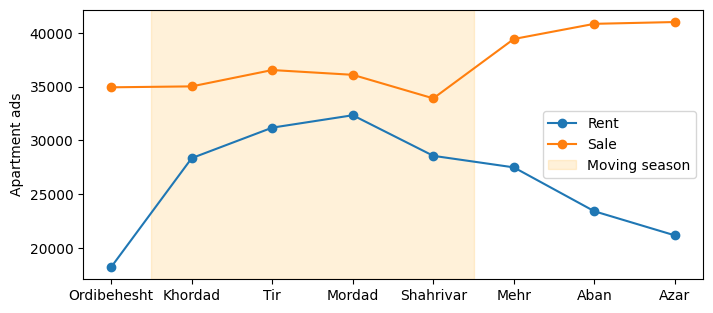

In [3]:
months = monthly.index.str.split().str[1]
plt.figure(figsize=(8, 3.5))
plt.plot(months, monthly['apartment-rent'], marker='o', label='Rent')
plt.plot(months, monthly['apartment-sell'], marker='o', label='Sale')
plt.axvspan(0.5, 4.5, color='orange', alpha=0.15, label='Moving season')
plt.ylabel('Apartment ads')
plt.legend()
plt.show()

## Supply

<div dir="rtl">

فرض صفر: سهم آگهی‌های اجاره از کل آگهی‌های آپارتمان در هر سه دوره یکسان است. آزمون Chi-square است و برای اندازه‌ی اثر از Cramér's V استفاده می‌کنیم.

</div>

In [4]:
table = pd.crosstab(apt['season'], apt['cat3_slug'])
chi2, p, dof, _ = stats.chi2_contingency(table)
v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"p-value = {p:.2g}, Cramer's V = {v:.2f}")
(pd.crosstab(apt['season'], apt['cat3_slug'], normalize='index') * 100).round(1)

p-value = 0, Cramer's V = 0.10


cat3_slug,apartment-rent,apartment-sell
season,,
moving_season,46.0,54.0
post_season,37.3,62.7
pre_season,34.3,65.7


<div dir="rtl">

فرض صفر رد می‌شود ولی اثر ضعیف است. با این حال جهت آن روشن است: در فصل جابه‌جایی ۴۶٪ آگهی‌ها اجاره‌اند، در حالی که قبل و بعد از فصل این سهم بین ۳۴ تا ۳۷٪ است.

</div>

## Price

<div dir="rtl">

اگر در فصل جابه‌جایی آگهی‌های بیشتری از شهرهای ارزان‌تر ثبت شوند، قیمت خام به‌اشتباه پایین‌تر دیده می‌شود. برای همین قیمت هر متر را بر میانه‌ی شهر خودش تقسیم می‌کنیم.

فرض صفر: قیمت نسبی اجاره در هر سه دوره یکسان است (آزمون Kruskal-Wallis).

</div>

In [5]:
rent = apt[apt['cat3_slug'] == 'apartment-rent'].copy()
rent['relative_price'] = rent['price_per_m2'] / rent.groupby('city_slug')['price_per_m2'].transform('median')

summary = rent.groupby('season').agg(
    raw_median_million=('price_per_m2', lambda s: s.median() / 1e6),
    relative_median=('relative_price', 'median'))
print(summary.round(3))

groups = [g.dropna() for _, g in rent.groupby('season')['relative_price']]
h, p = stats.kruskal(*groups)
n = sum(len(g) for g in groups)
print(f'p-value = {p:.2g}, epsilon squared = {(h - len(groups) + 1) / (n - len(groups)):.4f}')

               raw_median_million  relative_median
season                                            
moving_season               5.797            0.999
post_season                 6.000            1.002
pre_season                  6.250            1.012
p-value = 1e-12, epsilon squared = 0.0003


## Takeaway

<div dir="rtl">

قیمت خام در فصل جابه‌جایی کمی پایین‌تر دیده می‌شود، ولی قیمت نسبی در هر سه دوره تقریباً ۱ است و اندازه‌ی اثر عملاً صفر است. یعنی فصل جابه‌جایی تعداد آگهی‌های اجاره را بالا می‌برد ولی قیمت را تغییر نمی‌دهد، و تفاوت قیمت خام از تفاوت ترکیب شهرها می‌آید، نه از خود فصل.

برای مستأجر یعنی تابستان زمان بهتری برای پیدا کردن خانه است، چون انتخاب بیشتری دارد بدون اینکه قیمت بالاتر برود. برای پلتفرم هم یعنی ظرفیت و تبلیغات بخش اجاره باید در همین ماه‌ها بیشتر شود.

</div>